# 11 · E1 y E2 en NYUv2: color solo frente a color + profundidad sin máscara

Resultados de los dos primeros experimentos de la propuesta RGB-D, entrenados con `src/entrenar_rgbd.py`
(protocolo en su cabecera y en `DECISIONES.md`). Las predicciones se registraron antes de entrenar
(`DECISIONES.md`). Este notebook solo lee `runs/rgbd/*/resultado.json`; no entrena.

- **E1**: EfficientViT-B1 congelado + cabeza entrenada; no usa la profundidad.
- **E2**: E1 + DeFM ResNet-18 congelado, sumado en tres escalas sin máscara de validez.

Tasa de aprendizaje elegida en la validación por escenas (15 % de las escenas de entrenamiento): 1e-3 para E1 y
3e-4 para E2. Luego, tres semillas con las 795 imágenes y evaluación en las 654 de test, modelo final.

Uso de IA: notebook escrito con asistencia de IA (Claude, Anthropic); ver `DECISIONES.md`.

In [ ]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

RUNS = Path("..") / "runs" / "rgbd"
FIGS = Path("figs"); FIGS.mkdir(exist_ok=True)
CONDS = ["completa", "cruda", "aleatoria_10", "aleatoria_30", "aleatoria_50", "regiones", "sin"]
NOMBRE = {"completa": "completa", "cruda": "huecos reales", "aleatoria_10": "aleatorios 10 %",
          "aleatoria_30": "aleatorios 30 %", "aleatoria_50": "aleatorios 50 %", "regiones": "regiones (GeomPrompt s=0.5)",
          "sin": "sin profundidad"}

def leer(patron):
    return [json.loads(p.read_text(encoding="utf-8")) for p in sorted(RUNS.glob(patron + "/resultado.json"))]

val = {e: {r["lr"]: r["resultados"]["completa"]["miou"] for r in leer(f"val_{e}_lr*_s0")} for e in ("E1", "E2")}
print("validación por escenas (mIoU, semilla 0):")
for e, d in val.items():
    print(f"  {e}: " + "  ".join(f"lr {lr:g} -> {m:.2f}" for lr, m in sorted(d.items())))

R = {e: leer(f"{e}_lr*_s[0-9]") for e in ("E1", "E2")}
for e, rs in R.items():
    print(f"{e}: {len(rs)} semillas, lr {rs[0]['lr']:g}, {rs[0]['pasos']} pasos, "
          f"~{np.mean([r['minutos_entrenamiento'] for r in rs]):.0f} min cada una")

validación por escenas (mIoU, semilla 0):
  E1: lr 0.0003 -> 43.38  lr 0.001 -> 43.43  lr 0.003 -> 41.98
  E2: lr 0.0003 -> 45.66  lr 0.001 -> 45.59  lr 0.003 -> 44.57
E1: 3 semillas, lr 0.001, 5940 pasos, ~12 min cada una
E2: 3 semillas, lr 0.0003, 5940 pasos, ~16 min cada una


## 1. mIoU por condición (test, media ± desviación de 3 semillas)

In [ ]:
M = {e: np.array([[r["resultados"][c]["miou"] for c in CONDS] for r in rs]) for e, rs in R.items()}
print(f"{'condición':28s} {'E1':>13s} {'E2':>13s} {'E2 − E1':>9s} {'E2 − E2 completa':>17s}")
for j, c in enumerate(CONDS):
    e1, e2 = M["E1"][:, j], M["E2"][:, j]
    print(f"{NOMBRE[c]:28s} {e1.mean():6.2f} ± {e1.std(ddof=1):.2f} {e2.mean():6.2f} ± {e2.std(ddof=1):.2f} "
          f"{e2.mean() - e1.mean():+9.2f} {e2.mean() - M['E2'][:, 0].mean():+17.2f}")
print("\nE2 − E1 por semilla (misma semilla):")
for j, c in enumerate(CONDS):
    print(f"  {NOMBRE[c]:28s}", "  ".join(f"{d:+.2f}" for d in M["E2"][:, j] - M["E1"][:, j]))

condición                               E1            E2   E2 − E1  E2 − E2 completa
completa                      44.99 ± 0.30  47.31 ± 0.26     +2.32             +0.00
huecos reales                 44.99 ± 0.30  46.97 ± 0.52     +1.98             -0.35
aleatorios 10 %               44.99 ± 0.30  46.66 ± 0.36     +1.67             -0.66
aleatorios 30 %               44.99 ± 0.30  44.82 ± 0.32     -0.17             -2.50
aleatorios 50 %               44.99 ± 0.30  43.90 ± 0.12     -1.09             -3.42
regiones (GeomPrompt s=0.5)   44.99 ± 0.30  46.58 ± 0.28     +1.59             -0.74
sin profundidad               44.99 ± 0.30  42.25 ± 0.45     -2.74             -5.06

E2 − E1 por semilla (misma semilla):
  completa                     +2.37  +2.39  +2.21
  huecos reales                +2.10  +1.73  +2.10
  aleatorios 10 %              +1.80  +1.62  +1.58
  aleatorios 30 %              -0.06  -0.17  -0.29
  aleatorios 50 %              -1.13  -0.81  -1.34
  regiones (GeomPrompt s=0.

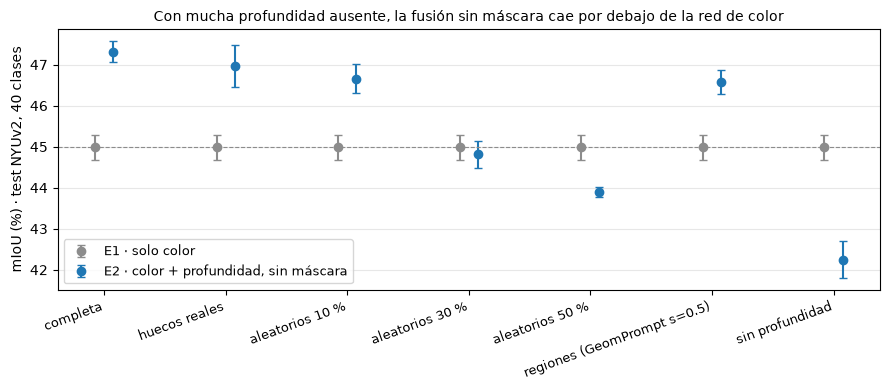

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(CONDS))
for k, (e, col) in enumerate([("E1", "0.55"), ("E2", "tab:blue")]):
    ax.errorbar(x + (k - 0.5) * 0.15, M[e].mean(0), yerr=M[e].std(0, ddof=1), fmt="o", color=col, capsize=3,
                label={"E1": "E1 · solo color", "E2": "E2 · color + profundidad, sin máscara"}[e])
ax.axhline(M["E1"].mean(), color="0.55", lw=0.8, ls="--")
ax.set_xticks(x); ax.set_xticklabels([NOMBRE[c] for c in CONDS], rotation=20, ha="right", fontsize=9)
ax.set_ylabel("mIoU (%) · test NYUv2, 40 clases"); ax.legend(fontsize=9); ax.grid(alpha=0.3, axis="y")
ax.set_title("Con mucha profundidad ausente, la fusión sin máscara cae por debajo de la red de color", fontsize=10)
fig.tight_layout(); fig.savefig(FIGS / "11_1_condiciones.png", dpi=140); plt.show()

## 2. Por clase: dónde ayuda la profundidad y dónde se pierde con huecos

Diferencia media E2 − E1 de la IoU por clase, con la profundidad completa y con los huecos reales. Se marcan las
clases con más profundidad ausente en `rawDepths` (`10_nyuv2_huecos` §2).

In [ ]:
clases = R["E1"][0]["clases"]
iou = {e: {c: np.array([r["resultados"][c]["iou_clase"] for r in rs]).mean(0) for c in CONDS} for e, rs in R.items()}
d_comp = iou["E2"]["completa"] - iou["E1"]["completa"]
d_cruda = iou["E2"]["cruda"] - iou["E1"]["cruda"]
orden = np.argsort(-d_comp)
reflejan = {"window", "ceiling", "mirror", "television"}
print("más ganancia con profundidad completa:")
for i in orden[:8]:
    print(f"  {clases[i]:18s} completa {d_comp[i]:+6.2f}   huecos reales {d_cruda[i]:+6.2f}")
print("menos ganancia (o pérdida):")
for i in orden[-6:]:
    print(f"  {clases[i]:18s} completa {d_comp[i]:+6.2f}   huecos reales {d_cruda[i]:+6.2f}")
print("\nclases con más huecos reales:")
for n in sorted(reflejan):
    i = clases.index(n)
    print(f"  {n:18s} completa {d_comp[i]:+6.2f}   huecos reales {d_cruda[i]:+6.2f}")

más ganancia con profundidad completa:
  mirror             completa  +6.36   huecos reales  +6.79
  toilet             completa  +5.67   huecos reales  +4.61
  pillow             completa  +5.48   huecos reales  +5.17
  chair              completa  +4.91   huecos reales  +4.67
  bathtub            completa  +4.45   huecos reales  +6.24
  dresser            completa  +3.98   huecos reales  +3.99
  lamp               completa  +3.88   huecos reales  +4.06
  counter            completa  +3.85   huecos reales  +2.74
menos ganancia (o pérdida):
  television         completa  +0.97   huecos reales  +1.28
  night stand        completa  +0.64   huecos reales  -0.87
  books              completa  -0.48   huecos reales  -0.72
  bag                completa  -0.71   huecos reales  -1.18
  paper              completa  -0.98   huecos reales  -1.03
  whiteboard         completa -11.21   huecos reales -10.68

clases con más huecos reales:
  ceiling            completa  +2.24   huecos reales  +1.07
  

## 3. Contraste con lo predicho

| | Predicho (registro) | Medido |
|---|---|---|
| E1, mIoU | «alrededor de 50 quizá 40 pero difícil más de 50» | ver §1 |
| E2 − E1, profundidad completa | «unos 5 puntos» | ver §1 |
| E2 con 50 % de huecos | «2 a 3 puntos debe caer» | ver §1, columna E2 − E2 completa |

> ✍️ **Lectura del equipo:** (pendiente)